# AgroReglas — demostración ejecutable

**Teoría de la Computación (INFO1148) · Universidad Católica de Temuco**

Este notebook recorre el proyecto completo con el código real del paquete `agroreglas`:
léxico (basado en el notebook docente), gramática, FIRST/FOLLOW, tabla LL(1), parser,
árbol concreto, AST, manejo de errores y casos de prueba.

El proyecto **solo reconoce la sintaxis**: no ejecuta reglas, no valida semántica y no controla equipos reales.

Para reejecutarlo: abrirlo desde `documentacion/` o desde la raíz del proyecto y ejecutar todas las celdas
(*Run All*), o bien `jupyter nbconvert --to notebook --execute --inplace documentacion/AgroReglas.ipynb`.

In [1]:
import platform, sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'agroreglas').is_dir() else Path.cwd().parent
sys.path[:0] = [str(RAIZ), str(RAIZ / 'tests')]

import agroreglas
from agroreglas import (analizar, analizar_tokens, tokenizar, analizador_lexico, construir_ast,
                        texto_ast, formula, derivacion_izquierda, ErrorAgro)
from agroreglas.gramatica import GRAMATICA, G0, G1, EPS
from agroreglas.ll1 import ANALISIS, analizar_gramatica

print('Python', platform.python_version())
print('Raíz del proyecto:', RAIZ.name)

Python 3.13.5
Raíz del proyecto: Proyecto_AgroReglas


## 1. Análisis léxico

El lexer conserva los patrones del notebook docente y agrega `DURING`, posiciones, `EOF`, `\r` y dígitos ASCII
(modificaciones M1–M7, documentadas en `agroreglas/lexico.py` y en el informe).

In [2]:
ENTRADA = '''WHEN humedad < 30 AND NOT (lluvia == TRUE OR viento > 40)
THEN regar sector_norte DURING 15 AND activar alarma;'''

print(f"{'lín:col':<8} {'tipo':<11} lexema")
for t in tokenizar(ENTRADA):
    print(f'{t.linea}:{t.columna:<6} {t.tipo:<11} {t.lexema}')

lín:col  tipo        lexema
1:1      WHEN        WHEN
1:6      ID          humedad
1:14     OP_REL      <
1:16     NUM         30
1:19     AND         AND
1:23     NOT         NOT
1:27     PARENT_IZQ  (
1:28     ID          lluvia
1:35     OP_REL      ==
1:38     TRUE        TRUE
1:43     OR          OR
1:46     ID          viento
1:53     OP_REL      >
1:55     NUM         40
1:57     PARENT_DER  )
2:1      THEN        THEN
2:6      ID          regar
2:12     ID          sector_norte
2:25     DURING      DURING
2:32     NUM         15
2:35     AND         AND
2:39     ID          activar
2:47     ID          alarma
2:53     PUNTO_COMA  ;
2:54     EOF         


Compatibilidad con la función original del notebook docente (se ejecuta su primera celda tal como fue entregada):

In [3]:
from test_lexico import cargar_lexer_docente, en_subconjunto_compartido
docente, _ = cargar_lexer_docente()

ejemplo = 'WHEN temperatura > 28 AND humedad < 40 THEN encender ventilador;'
print('Ejemplo del notebook, salidas idénticas:', docente(ejemplo) == analizador_lexico(ejemplo))

print('Diferencias documentadas:')
print('  M1 DURING :', docente('DURING'), '->', analizador_lexico('DURING'))
try:
    docente('WHEN\r\n')
except ValueError as e:
    print('  M4 \\r     : notebook -> ValueError', repr(str(e)), '| AgroReglas ->', analizador_lexico('WHEN\r\n'))
try:
    analizador_lexico('٣')
except ValueError as e:
    print('  M5 dígito Unicode: notebook ->', docente('٣'), '| AgroReglas ->', type(e).__name__)

Ejemplo del notebook, salidas idénticas: True
Diferencias documentadas:
  M1 DURING : [('ID', 'DURING')] -> [('DURING', 'DURING')]
  M4 \r     : notebook -> ValueError "Símbolo no reconocido: '\r'" | AgroReglas -> [('WHEN', 'WHEN')]
  M5 dígito Unicode: notebook -> [('NUM', '٣')] | AgroReglas -> ErrorLexico


## 2. Gramática libre de contexto G = (N, T, P, S)

In [4]:
g = GRAMATICA
print('S =', g.inicial)
print('N =', ', '.join(g.no_terminales))
print('T =', ', '.join(g.terminales))
print(f'|P| = {len(g.producciones)}   (ε = cadena vacía; EOF = marcador $ fuera de T)\n')
for p in g.producciones:
    print(f'({p.numero:>2}) {p}')

S = Programa
N = Programa, Resto, Regla, Condicion, ColaOr, Conjuncion, ColaAnd, Factor, Comparacion, Valor, Acciones, ColaAcciones, Accion, Duracion
T = WHEN, THEN, ID, OP_REL, NUM, TRUE, FALSE, NOT, AND, OR, PARENT_IZQ, PARENT_DER, DURING, PUNTO_COMA
|P| = 23   (ε = cadena vacía; EOF = marcador $ fuera de T)

( 1) Programa → Regla Resto
( 2) Resto → Regla Resto
( 3) Resto → ε
( 4) Regla → WHEN Condicion THEN Acciones PUNTO_COMA
( 5) Condicion → Conjuncion ColaOr
( 6) ColaOr → OR Conjuncion ColaOr
( 7) ColaOr → ε
( 8) Conjuncion → Factor ColaAnd
( 9) ColaAnd → AND Factor ColaAnd
(10) ColaAnd → ε
(11) Factor → NOT Factor
(12) Factor → PARENT_IZQ Condicion PARENT_DER
(13) Factor → Comparacion
(14) Comparacion → ID OP_REL Valor
(15) Valor → NUM
(16) Valor → TRUE
(17) Valor → FALSE
(18) Acciones → Accion ColaAcciones
(19) ColaAcciones → AND Accion ColaAcciones
(20) ColaAcciones → ε
(21) Accion → ID ID Duracion
(22) Duracion → DURING NUM
(23) Duracion → ε


## 3. Anulables, FIRST, FOLLOW y conjuntos de selección

In [5]:
def c(s): return '{' + ', '.join(ANALISIS.ordenar(s)) + '}'
print('Anulables:', [a for a in g.no_terminales if a in ANALISIS.anulables], '\n')
print(f"{'No terminal':<13} {'FIRST':<28} FOLLOW")
for a in g.no_terminales:
    print(f'{a:<13} {c(ANALISIS.first[a]):<28} {c(ANALISIS.follow[a])}')
print()
for p in g.producciones:
    print(f'SELECT({p.numero:>2}) = {c(ANALISIS.seleccion[p.numero]):<26} {p}')

Anulables: ['Resto', 'ColaOr', 'ColaAnd', 'ColaAcciones', 'Duracion'] 

No terminal   FIRST                        FOLLOW
Programa      {WHEN}                       {EOF}
Resto         {WHEN, ε}                    {EOF}
Regla         {WHEN}                       {WHEN, EOF}
Condicion     {ID, NOT, PARENT_IZQ}        {THEN, PARENT_DER}
ColaOr        {OR, ε}                      {THEN, PARENT_DER}
Conjuncion    {ID, NOT, PARENT_IZQ}        {THEN, OR, PARENT_DER}
ColaAnd       {AND, ε}                     {THEN, OR, PARENT_DER}
Factor        {ID, NOT, PARENT_IZQ}        {THEN, AND, OR, PARENT_DER}
Comparacion   {ID}                         {THEN, AND, OR, PARENT_DER}
Valor         {NUM, TRUE, FALSE}           {THEN, AND, OR, PARENT_DER}
Acciones      {ID}                         {PUNTO_COMA}
ColaAcciones  {AND, ε}                     {PUNTO_COMA}
Accion        {ID}                         {AND, PUNTO_COMA}
Duracion      {DURING, ε}                  {AND, PUNTO_COMA}

SELECT( 1) = {WHEN}  

## 4. Tabla LL(1) y comparación con las versiones previas G0 y G1

In [6]:
col = ANALISIS.columnas
abrev = {'PARENT_IZQ': '(', 'PARENT_DER': ')', 'PUNTO_COMA': ';', 'OP_REL': 'OP', 'DURING': 'DUR'}
print(f"{'':<13}" + ''.join(f'{abrev.get(t, t):>6}' for t in col))
for a in g.no_terminales:
    print(f'{a:<13}' + ''.join(f"{(ANALISIS.tabla[a, t].numero if (a, t) in ANALISIS.tabla else '·'):>6}" for t in col))
print(f'\nCeldas con producción: {len(ANALISIS.tabla)}; conflictos: {len(ANALISIS.conflictos)}')

               WHEN  THEN    ID    OP   NUM  TRUE FALSE   NOT   AND    OR     (     )   DUR     ;   EOF
Programa          1     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·
Resto             2     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     3
Regla             4     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·     ·
Condicion         ·     ·     5     ·     ·     ·     ·     5     ·     ·     5     ·     ·     ·     ·
ColaOr            ·     7     ·     ·     ·     ·     ·     ·     ·     6     ·     7     ·     ·     ·
Conjuncion        ·     ·     8     ·     ·     ·     ·     8     ·     ·     8     ·     ·     ·     ·
ColaAnd           ·    10     ·     ·     ·     ·     ·     ·     9    10     ·    10     ·     ·     ·
Factor            ·     ·    13     ·     ·     ·     ·    11     ·     ·    12     ·     ·     ·     ·
Comparacion       ·     ·    14     ·     ·     ·     ·     ·   

In [7]:
for otra in (G0, G1, GRAMATICA):
    a = analizar_gramatica(otra)
    print(f'{otra.nombre:<17} |P|={len(otra.producciones):>2}  recursión izq.: {a.recursion_directa or "—"}  '
          f'prefijos comunes: {[x[0] for x in a.prefijos] or "—"}  conflictos: {len(a.conflictos)}')

G0 (inicial)      |P|=16  recursión izq.: ['Condicion', 'Acciones']  prefijos comunes: ['Programa', 'Condicion', 'Accion']  conflictos: 6
G1 (precedencia)  |P|=18  recursión izq.: ['Condicion', 'Conjuncion', 'Acciones']  prefijos comunes: ['Programa', 'Accion']  conflictos: 9
G2 (final)        |P|=23  recursión izq.: —  prefijos comunes: —  conflictos: 0


## 5. Parser: árbol sintáctico concreto, AST y derivación

In [8]:
arbol = analizar(ENTRADA)
print(arbol.texto())

Programa
├── Regla
│   ├── WHEN 'WHEN'
│   ├── Condicion
│   │   ├── Conjuncion
│   │   │   ├── Factor
│   │   │   │   └── Comparacion
│   │   │   │       ├── ID 'humedad'
│   │   │   │       ├── OP_REL '<'
│   │   │   │       └── Valor
│   │   │   │           └── NUM '30'
│   │   │   └── ColaAnd
│   │   │       ├── AND 'AND'
│   │   │       ├── Factor
│   │   │       │   ├── NOT 'NOT'
│   │   │       │   └── Factor
│   │   │       │       ├── PARENT_IZQ '('
│   │   │       │       ├── Condicion
│   │   │       │       │   ├── Conjuncion
│   │   │       │       │   │   ├── Factor
│   │   │       │       │   │   │   └── Comparacion
│   │   │       │       │   │   │       ├── ID 'lluvia'
│   │   │       │       │   │   │       ├── OP_REL '=='
│   │   │       │       │   │   │       └── Valor
│   │   │       │       │   │   │           └── TRUE 'TRUE'
│   │   │       │       │   │   └── ColaAnd
│   │   │       │       │   │       └── ε
│   │   │       │       │   └── ColaOr
│   │   │     

In [9]:
ast = construir_ast(arbol)
print(texto_ast(ast))
print('\nCondición en notación prefija:', formula(ast.reglas[0].condicion))
print('Duraciones (DURING):', [a.duracion for a in ast.reglas[0].acciones])

Programa (1 regla)
└── Regla (línea 1)
    ├── Condición
    │   └── AND
    │       ├── humedad < 30
    │       └── NOT
    │           └── OR
    │               ├── lluvia == TRUE
    │               └── viento > 40
    └── Acciones
        ├── Acción
        │   ├── verbo: regar
        │   ├── objetivo: sector_norte
        │   └── DURING: 15 min
        └── Acción
            ├── verbo: activar
            └── objetivo: alarma

Condición en notación prefija: AND(humedad < 30, NOT(OR(lluvia == TRUE, viento > 40)))
Duraciones (DURING): [15, None]


In [10]:
producciones, formas = derivacion_izquierda(analizar('WHEN humedad < 30 THEN regar sur DURING 15;'))
print(' '.join(formas[0]))
for p, f in zip(producciones, formas[1:]):
    print(f'⇒ {" ".join(f):<62} [{p.numero}]')

Programa
⇒ Regla Resto                                                    [1]
⇒ WHEN Condicion THEN Acciones PUNTO_COMA Resto                  [4]
⇒ WHEN Conjuncion ColaOr THEN Acciones PUNTO_COMA Resto          [5]
⇒ WHEN Factor ColaAnd ColaOr THEN Acciones PUNTO_COMA Resto      [8]
⇒ WHEN Comparacion ColaAnd ColaOr THEN Acciones PUNTO_COMA Resto [13]
⇒ WHEN ID OP_REL Valor ColaAnd ColaOr THEN Acciones PUNTO_COMA Resto [14]
⇒ WHEN ID OP_REL NUM ColaAnd ColaOr THEN Acciones PUNTO_COMA Resto [15]
⇒ WHEN ID OP_REL NUM ColaOr THEN Acciones PUNTO_COMA Resto       [10]
⇒ WHEN ID OP_REL NUM THEN Acciones PUNTO_COMA Resto              [7]
⇒ WHEN ID OP_REL NUM THEN Accion ColaAcciones PUNTO_COMA Resto   [18]
⇒ WHEN ID OP_REL NUM THEN ID ID Duracion ColaAcciones PUNTO_COMA Resto [21]
⇒ WHEN ID OP_REL NUM THEN ID ID DURING NUM ColaAcciones PUNTO_COMA Resto [22]
⇒ WHEN ID OP_REL NUM THEN ID ID DURING NUM PUNTO_COMA Resto      [20]
⇒ WHEN ID OP_REL NUM THEN ID ID DURING NUM PUNTO_COMA            [

In [11]:
traza = []
analizar_tokens(tokenizar('WHEN h < 1 THEN a b;'), traza=traza)
for n, (pila, entrada, accion) in enumerate(traza, 1):
    print(f'{n:>2}  {pila:<50} {entrada:<34} {accion}')

 1  EOF Programa                                       WHEN ID OP_REL NUM THEN ID ID … EOF M[Programa, WHEN] = (1) Programa → Regla Resto
 2  EOF Resto Regla                                    WHEN ID OP_REL NUM THEN ID ID … EOF M[Regla, WHEN] = (4) Regla → WHEN Condicion THEN Acciones PUNTO_COMA
 3  EOF Resto PUNTO_COMA Acciones THEN Condicion WHEN  WHEN ID OP_REL NUM THEN ID ID … EOF coincidir WHEN
 4  EOF Resto PUNTO_COMA Acciones THEN Condicion       ID OP_REL NUM THEN ID ID PUNTO_COMA EOF M[Condicion, ID] = (5) Condicion → Conjuncion ColaOr
 5  EOF Resto PUNTO_COMA Acciones THEN ColaOr Conjuncion ID OP_REL NUM THEN ID ID PUNTO_COMA EOF M[Conjuncion, ID] = (8) Conjuncion → Factor ColaAnd
 6  EOF Resto PUNTO_COMA Acciones THEN ColaOr ColaAnd Factor ID OP_REL NUM THEN ID ID PUNTO_COMA EOF M[Factor, ID] = (13) Factor → Comparacion
 7  EOF Resto PUNTO_COMA Acciones THEN ColaOr ColaAnd Comparacion ID OP_REL NUM THEN ID ID PUNTO_COMA EOF M[Comparacion, ID] = (14) Comparacion → ID OP_REL 

Precedencia NOT > AND > OR, agrupación con paréntesis y asociatividad izquierda en el AST:

In [12]:
for cond in ['a == 1 OR b == 2 AND NOT c == 3', '(a == 1 OR b == 2) AND c == 3',
             'NOT (a == 1 AND b == 2)', 'a == 1 OR b == 2 OR c == 3']:
    print(f'{cond:<34} -> {formula(construir_ast(analizar(f"WHEN {cond} THEN x y;")).reglas[0].condicion)}')

a == 1 OR b == 2 AND NOT c == 3    -> OR(a == 1, AND(b == 2, NOT(c == 3)))
(a == 1 OR b == 2) AND c == 3      -> AND(OR(a == 1, b == 2), c == 3)
NOT (a == 1 AND b == 2)            -> NOT(AND(a == 1, b == 2))
a == 1 OR b == 2 OR c == 3         -> OR(OR(a == 1, b == 2), c == 3)


## 6. Manejo de errores (primer error, con línea, columna, esperados y puntero)

In [13]:
for texto in ['WHEN humedad < THEN regar sector_norte;',
              'WHEN (humedad < 30 THEN regar sector_sur;',
              'WHEN humedad < 30 THEN regar sector_sur DURING;',
              'WHEN humedad < 30 THEN regar sector_sur; basura',
              'WHEN humedad = 30 THEN regar sector_sur;',
              '']:
    try:
        analizar(texto)
    except ErrorAgro as error:
        print(error.mostrar(texto), end='\n\n')

Error sintáctico en línea 1, columna 16 (posición 15): se esperaba un valor (número entero, TRUE o FALSE) después del operador '<', pero se encontró la palabra reservada THEN.
  Esperados: NUM, TRUE, FALSE
  Cima de la pila: Valor
   1 | WHEN humedad < THEN regar sector_norte;
     |                ^^^^

Error sintáctico en línea 1, columna 20 (posición 19): se esperaba AND, OR o ')' después del número 30, pero se encontró la palabra reservada THEN. El '(' abierto en línea 1, columna 6 sigue sin cerrar.
  Esperados: AND, OR, PARENT_DER
  Cima de la pila: ColaAnd
   1 | WHEN (humedad < 30 THEN regar sector_sur;
     |                    ^^^^

Error sintáctico en línea 1, columna 47 (posición 46): se esperaba la duración en minutos (un número entero) después de DURING, pero se encontró el símbolo ';'.
  Esperados: NUM
  Cima de la pila: NUM
   1 | WHEN humedad < 30 THEN regar sector_sur DURING;
     |                                               ^

Error sintáctico en línea 1, columna 4

## 7. Casos de prueba documentados

In [14]:
from collections import Counter
from casos import CASOS, ejecutar, mostrar_entrada
filas = [ejecutar(caso) for caso in CASOS]
for f in filas:
    marca = '✓' if f['coincide'] else '✗'
    ubic = f" {f['error_obtenido']} {f['ubicacion_obtenida']}" if f['obtenido'] == 'RECHAZA' else ''
    print(f"{f['id']}  {f['esperado']:<8}{f['obtenido']:<8}{ubic:<17}{marca}  {f['entrada_mostrada'][:58]}")
total = Counter(f['categoria'] for f in filas)
print(f"\n{sum(f['coincide'] for f in filas)}/{len(filas)} coinciden con lo esperado:", dict(total))

V01  ACEPTA  ACEPTA                   ✓  WHEN humedad < 30 THEN regar sector_norte;
V02  ACEPTA  ACEPTA                   ✓  WHEN temperatura >= 35 THEN abrir valvula_1;
V03  ACEPTA  ACEPTA                   ✓  WHEN lluvia == TRUE THEN cerrar valvula_1;
V04  ACEPTA  ACEPTA                   ✓  WHEN lluvia != FALSE THEN activar alarma;
V05  ACEPTA  ACEPTA                   ✓  WHEN humedad <= 20 AND temperatura > 25 THEN regar sector_
V06  ACEPTA  ACEPTA                   ✓  WHEN humedad < 20 OR temperatura > 35 THEN regar sector_su
V07  ACEPTA  ACEPTA                   ✓  WHEN NOT lluvia == TRUE THEN regar sector_sur;
V08  ACEPTA  ACEPTA                   ✓  WHEN (humedad < 20 OR temperatura > 35) AND lluvia == FALS
V09  ACEPTA  ACEPTA                   ✓  WHEN humedad < 30 THEN regar sector_sur DURING 10;
V10  ACEPTA  ACEPTA                   ✓  WHEN humedad < 30 THEN regar sector_sur DURING 10 AND acti
V11  ACEPTA  ACEPTA                   ✓  WHEN humedad < 25 THEN regar invernadero D

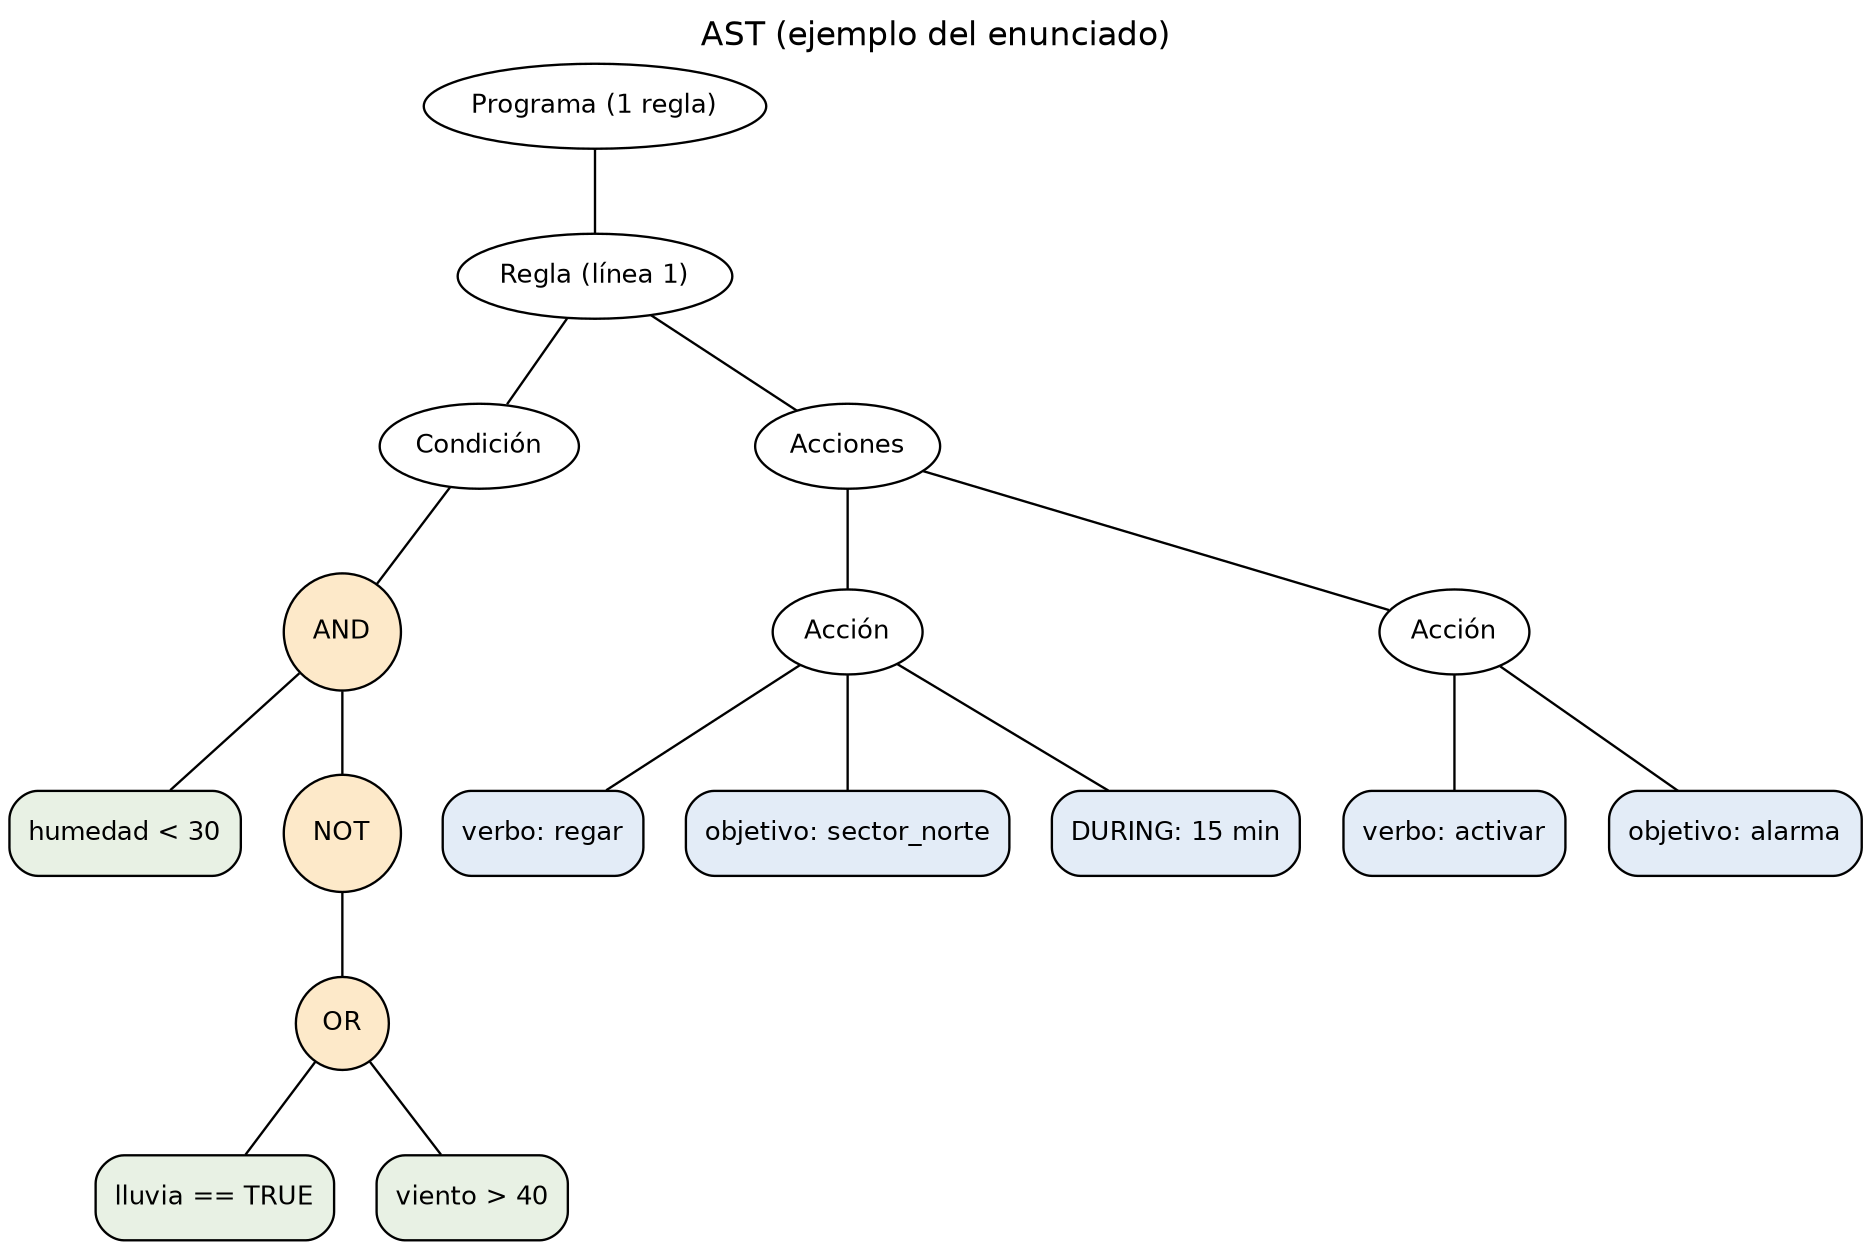

In [15]:
from IPython.display import Image, display
figura = RAIZ / 'resultados' / 'ast.png'
if figura.exists():
    display(Image(filename=str(figura), width=720))
else:
    print('Ejecute python3 generar_resultados.py (requiere Graphviz) para dibujar el AST.')

## Conclusión

La misma definición de la gramática (`agroreglas/gramatica.py`) alimenta FIRST, FOLLOW, la tabla LL(1) y el
parser. G2 no tiene conflictos; G0 y G1 sí, por recursión izquierda, prefijos comunes y ambigüedad.
El parser acepta y rechaza según los oráculos de los casos, construye el árbol concreto y el AST, e informa el
primer error con su ubicación. Limitaciones: sin recuperación de errores ni análisis semántico.